In [29]:
import joblib
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv('../tas2_yontem1.csv')

pipeline = joblib.load('kmeans_3segment.pkl')
yontem1df = df.copy()
yontem1df['max_price'] = df['max_price'].fillna(df['max_price'].median())
yontem1df['min_price'] = df['min_price'].fillna(df['min_price'].median())
yontem1df['gender'] = df['gender'].fillna("NULL")
yontem1df['message'] = df['message'].fillna("NULL")
yontem1df['comment'] = df['comment'].fillna("NULL")
yontem1df['deviceType'] = df['deviceType'].fillna("NULL")
yontem1df['categories'] = df['categories'].fillna("NULL")
yontem1df['contents'] = df['contents'].fillna("NULL")
df = yontem1df.copy()
predictions = pipeline.predict(df)
df['segment'] = predictions
df
df['segment'].value_counts()


segment
1    49
0    36
2    22
Name: count, dtype: int64

In [30]:
numerical_features = df.select_dtypes(include=['float64', 'int64']).columns

categorical_features = df.select_dtypes(include=['object']).columns
segment_summary_numeric = df.groupby('segment')[numerical_features].mean().round(2)

print("📊 Segment Bazlı Sayısal Özellik Ortalamaları:\n")
segment_summary_numeric

📊 Segment Bazlı Sayısal Özellik Ortalamaları:



,pageDuration,clicks,focusLossCount,sessionDuration,min_price,max_price
segment,,,,,,
0,2506683.83,14.47,56.00,31470828.36,34858.94,500.0
1,317881.80,40.14,25.39,13387463.49,639.52,500.0
2,1783455.23,83.00,133.00,36422086.00,661.50,500.0


📉 Segment Bazlı Sayısal Özellik Dağılımları:


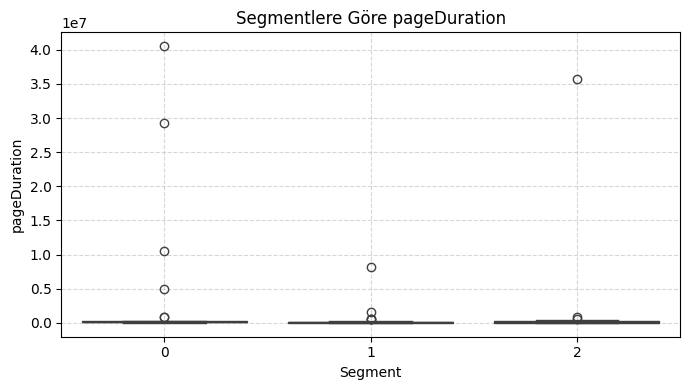

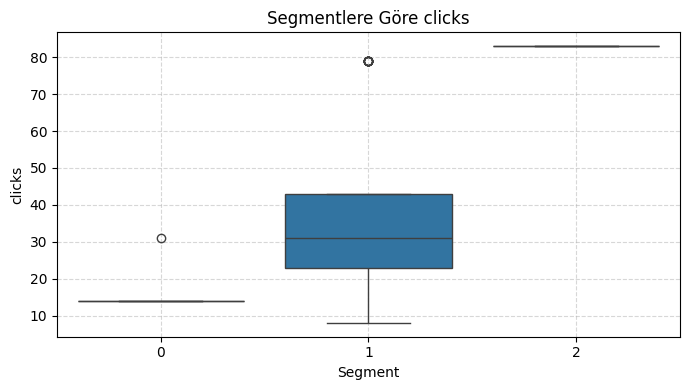

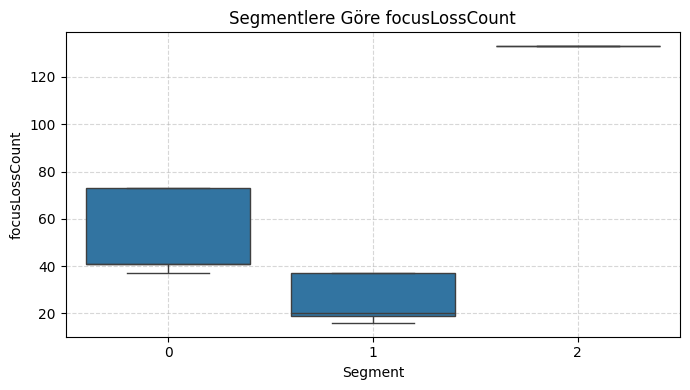

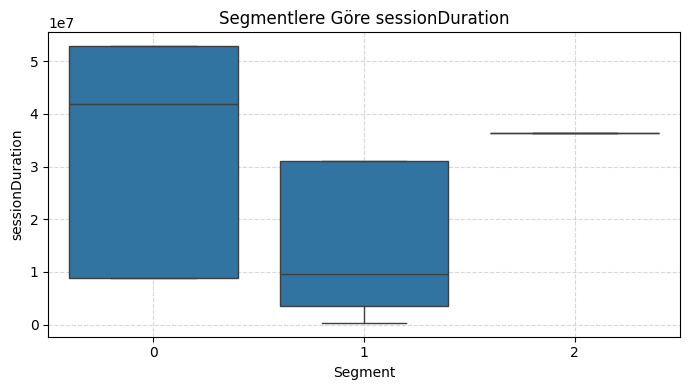

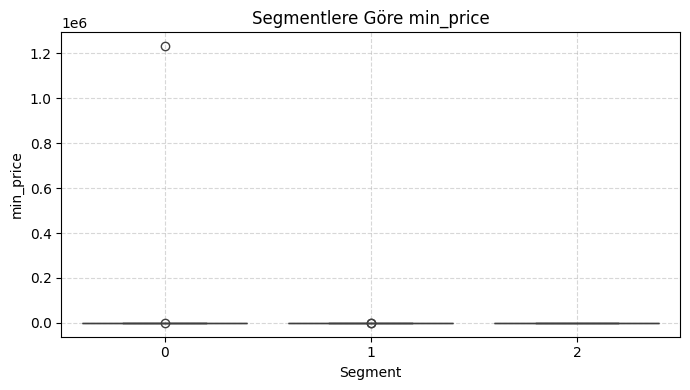

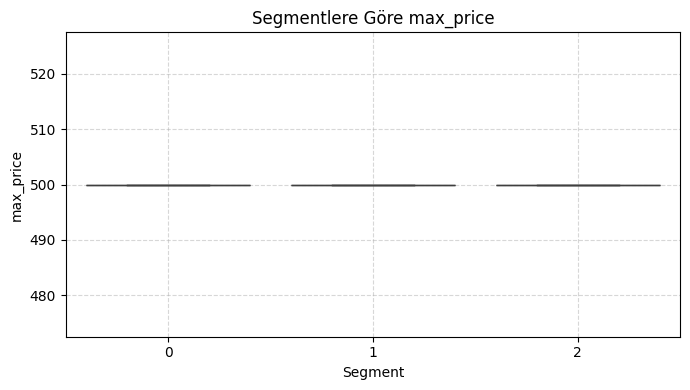

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

print("📉 Segment Bazlı Sayısal Özellik Dağılımları:")

for col in numerical_features:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x='segment', y=col)
    plt.title(f'Segmentlere Göre {col}')
    plt.xlabel('Segment')
    plt.ylabel(col)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


In [47]:
# Başlangıç: segmentleri sıralı şekilde indeks yap
crosstab_df = pd.DataFrame(index=sorted(df['segment'].unique()))

cols = ["deviceType", "gender"]
# Her kategorik özelliği işle
for col in cols:
    ct = pd.crosstab(df['segment'], df[col], normalize='index')
    ct.columns = [f"{col}_{val}" for val in ct.columns]
    crosstab_df = crosstab_df.join(ct, how='outer')

# Oranları % olarak göster (opsiyonel)
crosstab_df = (crosstab_df * 100).round(2)
crosstab_df = crosstab_df.reset_index().rename(columns={'index': 'segment'})

crosstab_df

,segment,deviceType_NULL,deviceType_desktop,deviceType_mobile,deviceType_tablet,gender_NULL,gender_male
0,0,2.78,97.22,0.0,0.00,100.00,0.00
1,1,30.61,28.57,0.0,40.82,95.92,4.08
2,2,0.00,0.00,100.0,0.00,100.00,0.00


In [45]:
numerical_features = df.select_dtypes(include=['float64', 'int64']).columns


segment_summary_numeric = df.groupby('segment')[numerical_features].mean().round(2)
segment_summary_numeric = segment_summary_numeric.reset_index()
segment_summary_numeric

,segment,pageDuration,clicks,focusLossCount,sessionDuration,min_price,max_price
0,0,2506683.83,14.47,56.00,31470828.36,34858.94,500.0
1,1,317881.80,40.14,25.39,13387463.49,639.52,500.0
2,2,1783455.23,83.00,133.00,36422086.00,661.50,500.0


In [49]:
merged_df = pd.merge(segment_summary_numeric, crosstab_df, on='segment')
merged_df

,segment,pageDuration,clicks,focusLossCount,sessionDuration,min_price,max_price,deviceType_NULL,deviceType_desktop,deviceType_mobile,deviceType_tablet,gender_NULL,gender_male
0,0,2506683.83,14.47,56.00,31470828.36,34858.94,500.0,2.78,97.22,0.0,0.00,100.00,0.00
1,1,317881.80,40.14,25.39,13387463.49,639.52,500.0,30.61,28.57,0.0,40.82,95.92,4.08
2,2,1783455.23,83.00,133.00,36422086.00,661.50,500.0,0.00,0.00,100.0,0.00,100.00,0.00


In [50]:
segment_json = merged_df.to_dict(orient='records')
import json
print(json.dumps(segment_json, indent=2))

[
  {
    "segment": 0,
    "pageDuration": 2506683.83,
    "clicks": 14.47,
    "focusLossCount": 56.0,
    "sessionDuration": 31470828.36,
    "min_price": 34858.94,
    "max_price": 500.0,
    "deviceType_NULL": 2.78,
    "deviceType_desktop": 97.22,
    "deviceType_mobile": 0.0,
    "deviceType_tablet": 0.0,
    "gender_NULL": 100.0,
    "gender_male": 0.0
  },
  {
    "segment": 1,
    "pageDuration": 317881.8,
    "clicks": 40.14,
    "focusLossCount": 25.39,
    "sessionDuration": 13387463.49,
    "min_price": 639.52,
    "max_price": 500.0,
    "deviceType_NULL": 30.61,
    "deviceType_desktop": 28.57,
    "deviceType_mobile": 0.0,
    "deviceType_tablet": 40.82,
    "gender_NULL": 95.92,
    "gender_male": 4.08
  },
  {
    "segment": 2,
    "pageDuration": 1783455.23,
    "clicks": 83.0,
    "focusLossCount": 133.0,
    "sessionDuration": 36422086.0,
    "min_price": 661.5,
    "max_price": 500.0,
    "deviceType_NULL": 0.0,
    "deviceType_desktop": 0.0,
    "deviceType_mobi

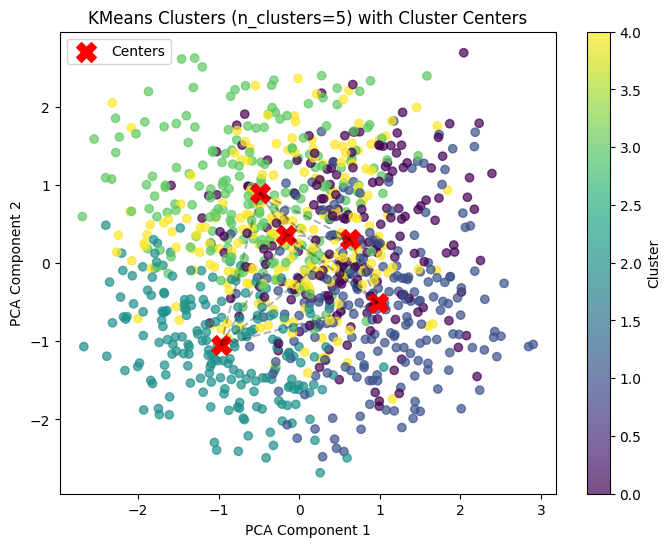

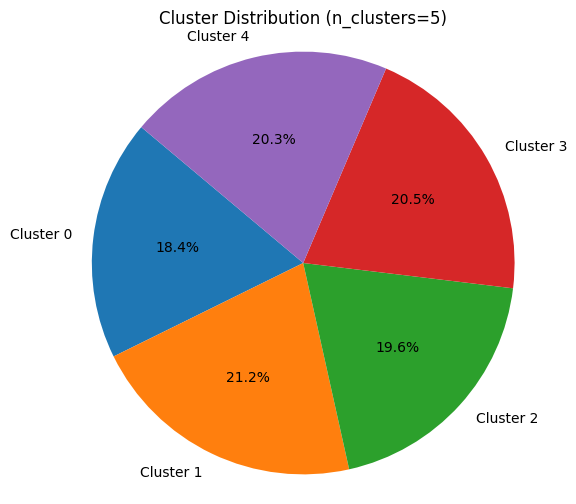

In [2]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd 
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
import joblib
df = pd.read_csv("../mocktest.csv",encoding="utf-8")
df['max_price'] = df['max_price'].fillna(df['max_price'].median())
df['min_price'] = df['min_price'].fillna(df['min_price'].median())
df['gender'] = df['gender'].fillna("NULL")
df['message'] = df['message'].fillna("NULL")
df['comment'] = df['comment'].fillna("NULL")
df['deviceType'] = df['deviceType'].fillna("NULL")
df['categories'] = df['categories'].fillna("NULL")
df['contents'] = df['contents'].fillna("NULL")



numerical_features = df.select_dtypes(include=['float64', 'int64']).columns

categorical_features = df.select_dtypes(include=['object']).columns

ss = StandardScaler()
ohe = OneHotEncoder(handle_unknown='ignore')
preprocessor = ColumnTransformer(
    transformers=[
        ('num', ss, numerical_features),
        ('cat', ohe, categorical_features)
    ]
)

for n_clusters in [2,3,5]:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('kmeans', kmeans)])
    pipeline.fit(df)
    df[f'cluster_{n_clusters}'] = pipeline.predict(df)
    joblib.dump(pipeline, f'kmeans_{n_clusters}segment.pkl')

# Preprocessing sonrası veriyi al
X_transformed = pipeline.named_steps['preprocessor'].transform(df)

# PCA uygula (örneğin 2 bileşen)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_transformed)

# KMeans merkezlerini PCA uzayına dönüştür
centers = pipeline.named_steps['kmeans'].cluster_centers_
centers_pca = pca.transform(centers)

# Görselleştir
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster_5'], cmap='viridis', alpha=0.7)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c='red', marker='X', s=200, label='Centers')

for i in range(len(centers_pca)):
    for j in range(i + 1, len(centers_pca)):
        plt.plot([centers_pca[i, 0], centers_pca[j, 0]], [centers_pca[i, 1], centers_pca[j, 1]], 'k--', alpha=0.3)

plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('KMeans Clusters (n_clusters=5) with Cluster Centers')
plt.colorbar(scatter, label='Cluster')
plt.legend()
plt.show()

# Pie chart for cluster distribution
cluster_counts = df['cluster_5'].value_counts().sort_index()
plt.figure(figsize=(6, 6))
plt.pie(cluster_counts, labels=[f'Cluster {i}' for i in cluster_counts.index], autopct='%1.1f%%', startangle=140)
plt.title('Cluster Distribution (n_clusters=5)')
plt.axis('equal')
plt.show()


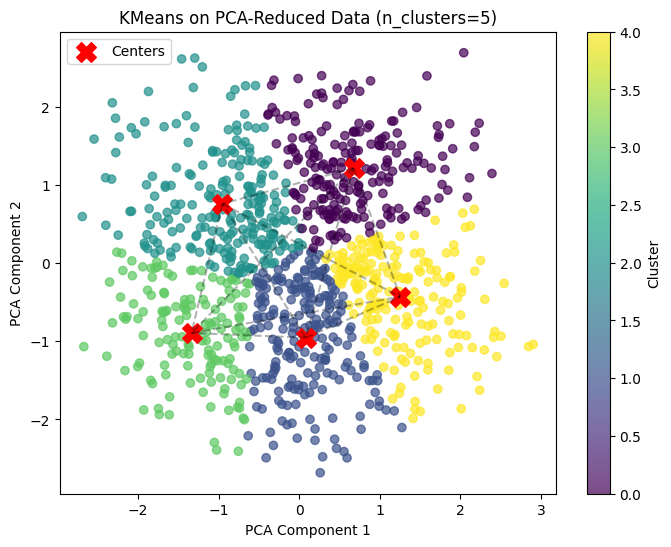

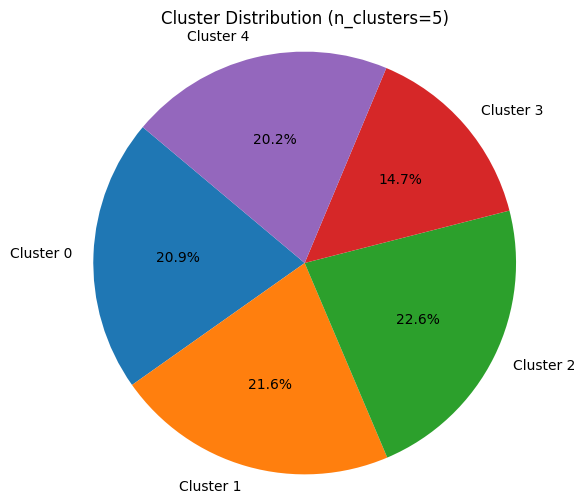

In [3]:
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import pandas as pd
import joblib

# 1. Veri okuma ve eksik değerleri doldurma
df = pd.read_csv("../mocktest.csv", encoding="utf-8")
df['max_price'] = df['max_price'].fillna(df['max_price'].median())
df['min_price'] = df['min_price'].fillna(df['min_price'].median())
for col in ['gender', 'message', 'comment', 'deviceType', 'categories', 'contents']:
    df[col] = df[col].fillna("NULL")

# 2. Özellik türlerini ayır
numerical_features = df.select_dtypes(include=['float64', 'int64']).columns
categorical_features = df.select_dtypes(include=['object']).columns

# 3. Ön işleme (standardizasyon + one-hot encoding)
ss = StandardScaler()
ohe = OneHotEncoder(handle_unknown='ignore')
preprocessor = ColumnTransformer([
    ('num', ss, numerical_features),
    ('cat', ohe, categorical_features)
])

# 4. Veriyi işleyelim (X artık sayısal ve ölçeklenmiş)
X_processed = preprocessor.fit_transform(df)

# 5. PCA uygulayalım (örneğin 2 boyuta indir)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_processed)

# 6. KMeans'i PCA çıktısında çalıştır
kmeans = KMeans(n_clusters=5, random_state=42)
clusters = kmeans.fit_predict(X_pca)

# 7. Küme sonuçlarını ekle
df['cluster_5'] = clusters

# 8. Görselleştirme: Scatter plot
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='viridis', alpha=0.7)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c='red', marker='X', s=200, label='Centers')

# Merkezler arası çizgi
for i in range(len(kmeans.cluster_centers_)):
    for j in range(i + 1, len(kmeans.cluster_centers_)):
        plt.plot(
            [kmeans.cluster_centers_[i, 0], kmeans.cluster_centers_[j, 0]],
            [kmeans.cluster_centers_[i, 1], kmeans.cluster_centers_[j, 1]],
            'k--', alpha=0.3
        )

plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.title('KMeans on PCA-Reduced Data (n_clusters=5)')
plt.colorbar(scatter, label='Cluster')
plt.legend()
plt.show()

# 9. Pasta Grafiği: Küme dağılımı
cluster_counts = df['cluster_5'].value_counts().sort_index()
plt.figure(figsize=(6, 6))
plt.pie(cluster_counts, labels=[f'Cluster {i}' for i in cluster_counts.index], autopct='%1.1f%%', startangle=140)
plt.title('Cluster Distribution (n_clusters=5)')
plt.axis('equal')
plt.show()
